In [17]:
import pandas as pd
import numpy as np

In [18]:
df = pd.read_csv('./data/i.csv', encoding='euc-kr')

In [19]:

# 1. 필요한 컬럼만 선택
cols = [
    "선명", "호출부호", "입항일시", "출항일시",
    "계선장소", "입출", "승객", "승객승선수", "승객하선수"
]

df_cruise = df[cols].copy()

# 2. 승객 관련 숫자 컬럼 정리
for col in ["승객", "승객승선수", "승객하선수"]:
    df_cruise[col] = pd.to_numeric(
        df_cruise[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

# 3. 입항 기록과 출항 기록 분리
arrival = df_cruise[df_cruise["입출"] == "입항"].copy()
departure = df_cruise[df_cruise["입출"] == "출항"].copy()

# 4. 동일 기항을 연결할 기준 컬럼
keys = ["선명", "호출부호", "입항일시", "출항일시", "계선장소"]

# 5. 입항·출항 승객 수 컬럼명 변경
arrival = arrival[
    keys + ["승객", "승객승선수", "승객하선수"]
].rename(columns={
    "승객": "입항승객수",
    "승객승선수": "입항_승객승선수",
    "승객하선수": "입항_승객하선수"
})

departure = departure[
    keys + ["승객", "승객승선수", "승객하선수"]
].rename(columns={
    "승객": "출항승객수",
    "승객승선수": "출항_승객승선수",
    "승객하선수": "출항_승객하선수"
})

# 6. 입항·출항을 하나의 기항 단위로 통합
df_pair = arrival.merge(
    departure,
    on=keys,
    how="outer",
    validate="one_to_one",
    indicator=True
)

# 7. 입항 - 출항으로 추정 하선객 수 계산
df_pair["추정하선객수"] = (
    df_pair["입항승객수"] - df_pair["출항승객수"]
)

# 8. 음수 여부 및 출항 승객수 결측 여부 확인
df_pair["음수여부"] = df_pair["추정하선객수"] < 0
df_pair["출항승객수_결측"] = df_pair["출항승객수"].isna()

print("통합 데이터:", df_pair.shape)
print("입항·출항 모두 연결:", (df_pair["_merge"] == "both").sum())
print("입항만 존재:", (df_pair["_merge"] == "left_only").sum())
print("출항만 존재:", (df_pair["_merge"] == "right_only").sum())
print("추정 하선객 수 음수:", df_pair["음수여부"].sum())
print("출항 승객 수 결측:", df_pair["출항승객수_결측"].sum())

통합 데이터: (1530, 15)
입항·출항 모두 연결: 1507
입항만 존재: 11
출항만 존재: 12
추정 하선객 수 음수: 483
출항 승객 수 결측: 16


In [26]:
df_pair.info()

<class 'pandas.DataFrame'>
RangeIndex: 1530 entries, 0 to 1529
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   선명        1530 non-null   str     
 1   호출부호      1530 non-null   str     
 2   입항일시      1530 non-null   str     
 3   출항일시      1530 non-null   str     
 4   계선장소      1530 non-null   str     
 5   입항승객수     1516 non-null   Float64 
 6   입항_승객승선수  538 non-null    Float64 
 7   입항_승객하선수  672 non-null    Float64 
 8   출항승객수     1514 non-null   Float64 
 9   출항_승객승선수  911 non-null    Float64 
 10  출항_승객하선수  1019 non-null   Float64 
 11  _merge    1530 non-null   category
 12  추정하선객수    1502 non-null   Float64 
 13  음수여부      1502 non-null   boolean 
 14  출항승객수_결측  1530 non-null   bool    
 15  원본_하선수    1056 non-null   Float64 
 16  원본_승선수    936 non-null    Float64 
dtypes: Float64(9), bool(1), boolean(1), category(1), str(5)
memory usage: 187.0 KB


In [20]:
# 입항·출항 기록에서 원본 승하선 인원 확인
df_pair["원본_하선수"] = (
    df_pair["입항_승객하선수"]
    .combine_first(df_pair["출항_승객하선수"])
)

df_pair["원본_승선수"] = (
    df_pair["입항_승객승선수"]
    .combine_first(df_pair["출항_승객승선수"])
)

# 음수 사례만 추출
negative = df_pair[df_pair["추정하선객수"] < 0].copy()

print("음수 사례:", len(negative))
print("원본 하선수 기록:", negative["원본_하선수"].notna().sum())
print("원본 승선수 기록:", negative["원본_승선수"].notna().sum())

# 음수 사례의 원본 기록 확인
display(
    negative[
        [
            "선명",
            "입항일시",
            "출항일시",
            "입항승객수",
            "출항승객수",
            "추정하선객수",
            "원본_하선수",
            "원본_승선수",
        ]
    ].head(20)
)

음수 사례: 483
원본 하선수 기록: 321
원본 승선수 기록: 421


,선명,입항일시,출항일시,입항승객수,출항승객수,추정하선객수,원본_하선수,원본_승선수
5,ADORA MAGIC CITY,2026-01-21 9:00,2026-01-21 22:00,1509.0,1516.0,-7.0,<NA>,7.0
18,ADORA MAGIC CITY,2026-05-03 7:00,2026-05-03 21:00,4801.0,4803.0,-2.0,1.0,3.0
34,ADORA MAGIC CITY,2026-10-04 7:52,2026-10-04 18:28,4209.0,4212.0,-3.0,<NA>,3.0
35,ADORA MAGIC CITY,2026-10-09 9:25,2026-10-09 21:56,4239.0,4274.0,-35.0,<NA>,35.0
41,ADORA MEDITERRANEA,2026-07-25 7:55,2026-07-25 16:15,1444.0,1445.0,-1.0,<NA>,1.0
42,ADORA MEDITERRANEA,2026-08-03 12:05,2026-08-03 21:52,1326.0,1327.0,-1.0,1.0,2.0
47,AIDADIVA,2026-01-12 7:00,2026-01-12 18:00,1908.0,1948.0,-40.0,1.0,47.0
53,ARCADIA,2017-03-10 5:30,2017-03-10 18:03,1943.0,1952.0,-9.0,4.0,13.0
55,ARTANIA,2024-03-17 7:33,2024-03-17 19:54,1033.0,1038.0,-5.0,<NA>,5.0
57,ASUKA II,2013-10-18 6:35,2013-10-18 18:00,604.0,611.0,-7.0,2.0,9.0


In [21]:
# 음수 사례 중 원본 하선수가 어느 행에 기록되어 있는지 확인
print(
    "입항 행에 하선수 기록:",
    negative["입항_승객하선수"].notna().sum()
)

print(
    "출항 행에 하선수 기록:",
    negative["출항_승객하선수"].notna().sum()
)

print(
    "입항·출항 양쪽 모두 하선수 기록:",
    (
        negative["입항_승객하선수"].notna()
        & negative["출항_승객하선수"].notna()
    ).sum()
)

# 양쪽 모두 하선수가 기록된 사례 확인
display(
    negative.loc[
        negative["입항_승객하선수"].notna()
        & negative["출항_승객하선수"].notna(),
        [
            "선명",
            "입항승객수",
            "출항승객수",
            "입항_승객하선수",
            "출항_승객하선수",
            "입항_승객승선수",
            "출항_승객승선수",
        ]
    ].head(20)
)

입항 행에 하선수 기록: 200
출항 행에 하선수 기록: 308
입항·출항 양쪽 모두 하선수 기록: 187


,선명,입항승객수,출항승객수,입항_승객하선수,출항_승객하선수,입항_승객승선수,출항_승객승선수
18,ADORA MAGIC CITY,4801.0,4803.0,1.0,1.0,<NA>,3.0
42,ADORA MEDITERRANEA,1326.0,1327.0,1.0,1.0,2.0,2.0
47,AIDADIVA,1908.0,1948.0,1.0,6.0,47.0,46.0
71,ASUKA II,407.0,417.0,2.0,4.0,14.0,14.0
90,AZAMARA PURSUIT,670.0,671.0,2.0,2.0,3.0,3.0
94,AZAMARA PURSUIT,665.0,670.0,1.0,2.0,7.0,7.0
95,AZAMARA PURSUIT,667.0,669.0,5.0,5.0,7.0,7.0
104,BREMEN,129.0,131.0,1.0,1.0,3.0,3.0
110,CELEBRITY MILLENNIUM,1621.0,1668.0,75.0,75.0,125.0,122.0
112,CELEBRITY MILLENNIUM,1680.0,1986.0,3.0,4.0,305.0,310.0


In [22]:
# 음수 사례 중 입항·출항 양쪽에 하선수가 있는 행
both = negative.loc[
    negative["입항_승객하선수"].notna()
    & negative["출항_승객하선수"].notna()
].copy()

# 두 값이 같은지 비교
both["하선수_일치"] = (
    both["입항_승객하선수"] == both["출항_승객하선수"]
)

print("양쪽 하선수 기록:", len(both))
print("하선수가 같은 경우:", both["하선수_일치"].sum())
print("하선수가 다른 경우:", (~both["하선수_일치"]).sum())

# 실제 값 비교
display(
    both[
        [
            "선명",
            "입항승객수",
            "출항승객수",
            "입항_승객하선수",
            "출항_승객하선수",
            "입항_승객승선수",
            "출항_승객승선수",
            "추정하선객수",
        ]
    ].head(30)
)

양쪽 하선수 기록: 187
하선수가 같은 경우: 135
하선수가 다른 경우: 52


,선명,입항승객수,출항승객수,입항_승객하선수,출항_승객하선수,입항_승객승선수,출항_승객승선수,추정하선객수
18,ADORA MAGIC CITY,4801.0,4803.0,1.0,1.0,<NA>,3.0,-2.0
42,ADORA MEDITERRANEA,1326.0,1327.0,1.0,1.0,2.0,2.0,-1.0
47,AIDADIVA,1908.0,1948.0,1.0,6.0,47.0,46.0,-40.0
71,ASUKA II,407.0,417.0,2.0,4.0,14.0,14.0,-10.0
90,AZAMARA PURSUIT,670.0,671.0,2.0,2.0,3.0,3.0,-1.0
94,AZAMARA PURSUIT,665.0,670.0,1.0,2.0,7.0,7.0,-5.0
95,AZAMARA PURSUIT,667.0,669.0,5.0,5.0,7.0,7.0,-2.0
104,BREMEN,129.0,131.0,1.0,1.0,3.0,3.0,-2.0
110,CELEBRITY MILLENNIUM,1621.0,1668.0,75.0,75.0,125.0,122.0,-47.0
112,CELEBRITY MILLENNIUM,1680.0,1986.0,3.0,4.0,305.0,310.0,-306.0


In [23]:
# 양쪽 하선수가 다른 52건 확인
different = both.loc[
    both["입항_승객하선수"] != both["출항_승객하선수"]
].copy()

different["하선수_차이"] = (
    different["입항_승객하선수"]
    - different["출항_승객하선수"]
)

display(
    different[
        [
            "선명",
            "입항일시",
            "출항일시",
            "입항승객수",
            "출항승객수",
            "입항_승객하선수",
            "출항_승객하선수",
            "입항_승객승선수",
            "출항_승객승선수",
            "하선수_차이",
        ]
    ].head(30)
)

,선명,입항일시,출항일시,입항승객수,출항승객수,입항_승객하선수,출항_승객하선수,입항_승객승선수,출항_승객승선수,하선수_차이
47,AIDADIVA,2026-01-12 7:00,2026-01-12 18:00,1908.0,1948.0,1.0,6.0,47.0,46.0,-5.0
71,ASUKA II,2017-04-24 11:50,2017-04-24 21:54,407.0,417.0,2.0,4.0,14.0,14.0,-2.0
94,AZAMARA PURSUIT,2026-05-01 8:45,2026-05-02 15:03,665.0,670.0,1.0,2.0,7.0,7.0,-1.0
112,CELEBRITY MILLENNIUM,2016-10-11 6:00,2016-10-11 15:00,1680.0,1986.0,3.0,4.0,305.0,310.0,-1.0
118,CELEBRITY MILLENNIUM,2017-10-19 6:45,2017-10-19 16:45,2110.0,2116.0,3.0,10.0,9.0,16.0,-7.0
121,CELEBRITY MILLENNIUM,2018-10-08 6:18,2018-10-08 19:42,2145.0,2146.0,11.0,13.0,14.0,14.0,-2.0
136,CELEBRITY MILLENNIUM,2024-07-21 7:24,2024-07-21 18:12,2480.0,2483.0,7.0,9.0,12.0,12.0,-2.0
146,CELEBRITY MILLENNIUM,2025-06-26 6:24,2025-06-26 17:03,2343.0,2344.0,6.0,5.0,7.0,6.0,1.0
148,CELEBRITY MILLENNIUM,2025-08-01 6:15,2025-08-01 17:06,2443.0,2450.0,2.0,51.0,9.0,58.0,-49.0
150,CELEBRITY MILLENNIUM,2025-09-06 8:40,2025-09-06 18:46,2163.0,2169.0,1.0,2.0,8.0,8.0,-1.0


In [24]:
# 원본 승객 승·하선수 분포 확인
for col in ["승객", "승객승선수", "승객하선수"]:
    print(f"\n[{col}]")
    print(df[col].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]))
    print("결측:", df[col].isna().sum())
    print("0인 값:", (df[col] == 0).sum())


[승객]
count    3030.000000
mean     1822.519472
std      1403.546192
min         2.000000
25%       468.000000
50%      1869.000000
75%      2760.000000
90%      3677.000000
99%      5250.520000
max      5466.000000
Name: 승객, dtype: float64
결측: 7
0인 값: 0

[승객승선수]
count    1449.000000
mean      153.925466
std       472.265482
min         0.000000
25%         2.000000
50%         5.000000
75%        31.000000
90%       295.800000
99%      2429.680000
max      2800.000000
Name: 승객승선수, dtype: float64
결측: 1588
0인 값: 4

[승객하선수]
count    1691.000000
mean      152.214075
std       469.399043
min         0.000000
25%         3.000000
50%         6.000000
75%        33.000000
90%       306.000000
99%      2442.800000
max      2785.000000
Name: 승객하선수, dtype: float64
결측: 1346
0인 값: 4


In [25]:
# 하선수가 전체 승객 수보다 큰 행 확인
df["승객"] = pd.to_numeric(
    df["승객"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

df["승객하선수"] = pd.to_numeric(
    df["승객하선수"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

print(
    "하선수 > 승객수:",
    (df["승객하선수"] > df["승객"]).sum()
)

display(
    df.loc[
        df["승객하선수"] > df["승객"],
        ["선명", "입출", "승객", "승객승선수", "승객하선수"]
    ].head(20)
)

하선수 > 승객수: 89


,선명,입출,승객,승객승선수,승객하선수
182,PACIFIC VENUS,출항,52.0,NaN,280.0
400,MARINER OF THE SEAS,출항,20.0,1.0,2423.0
412,OCEAN DREAM,출항,61.0,NaN,451.0
487,OCEAN DREAM,출항,130.0,NaN,537.0
670,COSTA VICTORIA,출항,944.0,939.0,1713.0
672,GOLDEN PRINCESS,출항,1257.0,6.0,1474.0
753,OCEAN DREAM,출항,99.0,NaN,549.0
1044,SKYSEA GOLDEN ERA,출항,131.0,118.0,1415.0
1050,COSTA VICTORIA,출항,206.0,198.0,1779.0
1160,COSTA NEOROMANTICA,출항,721.0,721.0,1350.0


In [28]:
import numpy as np

conditions = [
    (df_pair["_merge"] != "both").fillna(False).to_numpy(dtype=bool),
    df_pair["입항승객수"].isna().to_numpy(dtype=bool),
    df_pair["출항승객수"].isna().to_numpy(dtype=bool),
    (df_pair["추정하선객수"] < 0).fillna(False).to_numpy(dtype=bool)
]

choices = [
    "입항·출항 기록 불일치",
    "입항 승객 수 결측",
    "출항 승객 수 결측",
    "음수 추정값 확인 필요"
]

df_pair["하선추정_상태"] = np.select(
    conditions,
    choices,
    default="정상 추정값"
)

print(df_pair["하선추정_상태"].value_counts())

하선추정_상태
정상 추정값          1019
음수 추정값 확인 필요     483
입항·출항 기록 불일치      23
출항 승객 수 결측         5
Name: count, dtype: int64


In [29]:
# 입항일시를 날짜 형식으로 변환
df_pair["입항일시"] = pd.to_datetime(
    df_pair["입항일시"],
    errors="coerce"
)

df_pair["연도"] = df_pair["입항일시"].dt.year

# 연도별 상태 건수
year_status = pd.crosstab(
    df_pair["연도"],
    df_pair["하선추정_상태"]
)

display(year_status)

# 연도별 음수 비율
negative_by_year = (
    df_pair.assign(
        음수여부=df_pair["하선추정_상태"].eq("음수 추정값 확인 필요")
    )
    .groupby("연도")
    .agg(
        전체건수=("음수여부", "size"),
        음수건수=("음수여부", "sum")
    )
)

negative_by_year["음수비율(%)"] = (
    negative_by_year["음수건수"]
    / negative_by_year["전체건수"]
    * 100
).round(1)

display(negative_by_year)

하선추정_상태,음수 추정값 확인 필요,입항·출항 기록 불일치,정상 추정값,출항 승객 수 결측
연도,,,,
2013,26,2,77,2
2014,28,6,73,0
2015,19,2,44,0
2016,70,1,135,0
2017,31,0,58,0
2018,32,2,47,0
2019,43,0,64,0
2023,30,0,75,0
2024,32,2,80,1


,전체건수,음수건수,음수비율(%)
연도,,,
2013,107,26,24.3
2014,107,28,26.2
2015,65,19,29.2
2016,206,70,34.0
2017,89,31,34.8
2018,81,32,39.5
2019,107,43,40.2
2023,105,30,28.6
2024,115,32,27.8


In [30]:
# 음수 추정값만 추출
negative = df_pair[
    df_pair["추정하선객수"] < 0
].copy()

# 입항·출항 원본 하선 인원 중 하나라도 있는지 확인
negative["원본하선수_입항존재"] = (
    negative["입항_승객하선수"].notna()
)

negative["원본하선수_출항존재"] = (
    negative["출항_승객하선수"].notna()
)

negative["원본하선수_둘다존재"] = (
    negative["원본하선수_입항존재"]
    & negative["원본하선수_출항존재"]
)

negative["원본하선수_둘다없음"] = (
    negative["입항_승객하선수"].isna()
    & negative["출항_승객하선수"].isna()
)

# 연도별 현황
negative_by_year = negative.groupby("연도").agg(
    음수건수=("추정하선객수", "size"),
    입항하선수_존재=("원본하선수_입항존재", "sum"),
    출항하선수_존재=("원본하선수_출항존재", "sum"),
    양쪽하선수_존재=("원본하선수_둘다존재", "sum"),
    양쪽모두결측=("원본하선수_둘다없음", "sum")
)

display(negative_by_year)

,음수건수,입항하선수_존재,출항하선수_존재,양쪽하선수_존재,양쪽모두결측
연도,,,,,
2013,26,7,12,5,12
2014,28,5,15,4,12
2015,19,9,16,9,3
2016,70,19,37,18,32
2017,31,3,12,3,19
2018,32,3,13,2,18
2019,43,7,31,4,9
2023,30,10,21,10,9
2024,32,15,22,14,9


In [31]:
# 음수 추정값 중 원본 하선 인원이 존재하는 행
negative = df_pair.loc[
    df_pair["추정하선객수"] < 0
].copy()

# 입항·출항 각각의 승객 수와 하선 인원 비교
display(
    negative[
        [
            "연도", "선명",
            "입항승객수", "입항_승객하선수",
            "출항승객수", "출항_승객하선수"
        ]
    ].head(30)
)

,연도,선명,입항승객수,입항_승객하선수,출항승객수,출항_승객하선수
5,2026,ADORA MAGIC CITY,1509.0,<NA>,1516.0,<NA>
18,2026,ADORA MAGIC CITY,4801.0,1.0,4803.0,1.0
34,2026,ADORA MAGIC CITY,4209.0,<NA>,4212.0,<NA>
35,2026,ADORA MAGIC CITY,4239.0,<NA>,4274.0,<NA>
41,2026,ADORA MEDITERRANEA,1444.0,<NA>,1445.0,<NA>
42,2026,ADORA MEDITERRANEA,1326.0,1.0,1327.0,1.0
47,2026,AIDADIVA,1908.0,1.0,1948.0,6.0
53,2017,ARCADIA,1943.0,<NA>,1952.0,4.0
55,2024,ARTANIA,1033.0,<NA>,1038.0,<NA>
57,2013,ASUKA II,604.0,2.0,611.0,<NA>


In [32]:
import numpy as np

# 원래 계산한 값은 보존
df_pair["추정하선객수_원본"] = df_pair["추정하선객수"]

# 입항·출항 기록이 연결되고 승객 수가 모두 있으며,
# 계산 결과가 0 이상인 경우만 분석용 값으로 사용
valid = (
    df_pair["_merge"].eq("both")
    & df_pair["입항승객수"].notna()
    & df_pair["출항승객수"].notna()
    & df_pair["추정하선객수"].ge(0)
)

df_pair["추정하선객수_분석용"] = np.where(
    valid,
    df_pair["추정하선객수"],
    np.nan
)

print("전체 기록:", len(df_pair))
print("분석용 값 존재:", df_pair["추정하선객수_분석용"].notna().sum())
print("제외된 기록:", df_pair["추정하선객수_분석용"].isna().sum())

전체 기록: 1530
분석용 값 존재: 1019
제외된 기록: 511


In [33]:
yearly_alighting = (
    df_pair.groupby("연도")
    .agg(
        전체기록수=("추정하선객수_원본", "size"),
        분석가능건수=("추정하선객수_분석용", "count"),
        추정하선객수_합계=("추정하선객수_분석용", "sum"),
        추정하선객수_평균=("추정하선객수_분석용", "mean"),
        추정하선객수_중앙값=("추정하선객수_분석용", "median")
    )
)

yearly_alighting["분석가능비율(%)"] = (
    yearly_alighting["분석가능건수"]
    / yearly_alighting["전체기록수"]
    * 100
).round(1)

display(yearly_alighting.round(1))

,전체기록수,분석가능건수,추정하선객수_합계,추정하선객수_평균,추정하선객수_중앙값,분석가능비율(%)
연도,,,,,,
2013,107,77,3316.0,43.1,7.0,72.0
2014,107,73,5484.0,75.1,5.0,68.2
2015,65,44,1846.0,42.0,6.0,67.7
2016,206,135,4561.0,33.8,2.0,65.5
2017,89,58,6373.0,109.9,3.0,65.2
2018,81,47,5771.0,122.8,5.0,58.0
2019,107,64,8897.0,139.0,6.0,59.8
2023,105,75,8331.0,111.1,3.0,71.4
2024,115,80,4903.0,61.3,2.0,69.6


In [34]:
# 입항 기록만 추출
arrival_df = df[df["입출"] == "입항"].copy()

arrival_df["승객"] = pd.to_numeric(
    arrival_df["승객"].astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

arrival_df["입항일시"] = pd.to_datetime(
    arrival_df["입항일시"],
    errors="coerce"
)

arrival_df["연도"] = arrival_df["입항일시"].dt.year

yearly_cruise = (
    arrival_df.groupby("연도")
    .agg(
        입항횟수=("선명", "size"),
        승객수_합계=("승객", "sum"),
        승객수_평균=("승객", "mean"),
        승객수_중앙값=("승객", "median")
    )
)

display(yearly_cruise.round(1))

,입항횟수,승객수_합계,승객수_평균,승객수_중앙값
연도,,,,
2013,106,199170.0,1879.0,1946.0
2014,104,240251.0,2310.1,2491.5
2015,64,161654.0,2525.8,2551.0
2016,205,560887.0,2736.0,2705.0
2017,89,158128.0,1776.7,1911.0
2018,80,128795.0,1609.9,1386.5
2019,107,189053.0,1766.9,1615.0
2023,105,151351.0,1441.4,804.0
2024,114,152892.0,1341.2,1034.5


In [35]:
yearly_cruise["입항횟수_전년대비(%)"] = (
    yearly_cruise["입항횟수"].pct_change() * 100
).round(1)

yearly_cruise["승객수_전년대비(%)"] = (
    yearly_cruise["승객수_합계"].pct_change() * 100
).round(1)

yearly_cruise["회당승객수_전년대비(%)"] = (
    yearly_cruise["승객수_평균"].pct_change() * 100
).round(1)

display(
    yearly_cruise[
        [
            "입항횟수",
            "승객수_합계",
            "승객수_평균",
            "입항횟수_전년대비(%)",
            "승객수_전년대비(%)",
            "회당승객수_전년대비(%)"
        ]
    ].round(1)
)

,입항횟수,승객수_합계,승객수_평균,입항횟수_전년대비(%),승객수_전년대비(%),회당승객수_전년대비(%)
연도,,,,,,
2013,106,199170.0,1879.0,NaN,<NA>,<NA>
2014,104,240251.0,2310.1,-1.9,20.6,22.9
2015,64,161654.0,2525.8,-38.5,-32.7,9.3
2016,205,560887.0,2736.0,220.3,247.0,8.3
2017,89,158128.0,1776.7,-56.6,-71.8,-35.1
2018,80,128795.0,1609.9,-10.1,-18.6,-9.4
2019,107,189053.0,1766.9,33.7,46.8,9.7
2023,105,151351.0,1441.4,-1.9,-19.9,-18.4
2024,114,152892.0,1341.2,8.6,1.0,-7.0


In [36]:
display(
    yearly_cruise[
        [
            "입항횟수",
            "승객수_합계",
            "승객수_평균",
            "입항횟수_전년대비(%)",
            "승객수_전년대비(%)",
            "회당승객수_전년대비(%)"
        ]
    ].to_string()
)

'      입항횟수    승객수_합계       승객수_평균  입항횟수_전년대비(%)  승객수_전년대비(%)  회당승객수_전년대비(%)\n연도                                                                         \n2013   106  199170.0  1878.962264           NaN         <NA>           <NA>\n2014   104  240251.0  2310.105769          -1.9         20.6           22.9\n2015    64  161654.0   2525.84375         -38.5        -32.7            9.3\n2016   205  560887.0  2736.034146         220.3        247.0            8.3\n2017    89  158128.0  1776.719101         -56.6        -71.8          -35.1\n2018    80  128795.0    1609.9375         -10.1        -18.6           -9.4\n2019   107  189053.0  1766.850467          33.7         46.8            9.7\n2023   105  151351.0  1441.438095          -1.9        -19.9          -18.4\n2024   114  152892.0  1341.157895           8.6          1.0           -7.0\n2025   205  258697.0  1274.369458          79.8         69.2           -5.0\n2026   339  571841.0  1686.846608          65.4        121.0           32.4

In [38]:
growth = yearly_cruise[
    ["입항횟수", "승객수_합계", "승객수_평균"]
].copy()

growth["입항횟수_전년대비(%)"] = (
    growth["입항횟수"].pct_change() * 100
).round(1)

growth["승객수_전년대비(%)"] = (
    growth["승객수_합계"].pct_change() * 100
).round(1)

growth["회당승객수_전년대비(%)"] = (
    growth["승객수_평균"].pct_change() * 100
).round(1)

display(growth)

,입항횟수,승객수_합계,승객수_평균,입항횟수_전년대비(%),승객수_전년대비(%),회당승객수_전년대비(%)
연도,,,,,,
2013,106,199170.0,1878.962264,NaN,<NA>,<NA>
2014,104,240251.0,2310.105769,-1.9,20.6,22.9
2015,64,161654.0,2525.84375,-38.5,-32.7,9.3
2016,205,560887.0,2736.034146,220.3,247.0,8.3
2017,89,158128.0,1776.719101,-56.6,-71.8,-35.1
2018,80,128795.0,1609.9375,-10.1,-18.6,-9.4
2019,107,189053.0,1766.850467,33.7,46.8,9.7
2023,105,151351.0,1441.438095,-1.9,-19.9,-18.4
2024,114,152892.0,1341.157895,8.6,1.0,-7.0


In [39]:
# 중국 관련 크루즈 구분에 활용할 열 확인
cols = ["선명", "호출부호", "전출항지", "차항지"]

for col in cols:
    print(f"\n[{col}]")
    print("결측치:", df[col].isna().sum())
    print("고유값 수:", df[col].nunique())
    display(df[col].value_counts(dropna=False).head(20))


[선명]
결측치: 0
고유값 수: 116


선명
DIAMOND PRINCESS        312
EASTERN VENUS           208
COSTA SERENA            144
CELEBRITY MILLENNIUM    124
SAPPHIRE PRINCESS       116
MARINER OF THE SEAS     106
COSTA VICTORIA          102
MITSUI OCEAN FUJI        96
QUANTUM OF THE SEAS      92
COSTA NEOROMANTICA       90
MSC BELLISSIMA           90
COSTA ATLANTICA          82
ADORA MAGIC CITY         74
LE SOLEAL                68
VOYAGER OF THE SEAS      60
DREAM                    56
SKYSEA GOLDEN ERA        54
MSC LIRICA               52
SPECTRUM OF THE SEAS     52
ZHAO SHANG YI DUN        50
Name: count, dtype: int64


[호출부호]
결측치: 0
고유값 수: 116


호출부호
2HFZ7      244
3E7469     208
ICAZ       144
9HJF9      124
IBCR       120
2HFZ6      116
C6FV9      106
IBLC       102
C6XC6       98
C6BH8       92
9HA4902     90
IBLQ        82
HOA2246     74
FIHV        68
C6SE5       60
ZCHI3       56
D5YS3       56
9HJI9       54
HOPW        52
5BDR6       52
Name: count, dtype: int64


[전출항지]
결측치: 0
고유값 수: 90


전출항지
제주                   384
NAGASAKI             322
SAKAIMINATO          260
SHANGHAI             242
HIROSHIMA            166
FUKUOKA, FUKUOKA     144
SASEBO               112
TIANJIN              106
KOBE                 104
서귀포                   96
YOKOHAMA              94
KANAZAWA              88
HAKATA/FUKUOKA        86
KAGOSHIMA             72
KEELUNG (CHILUNG)     68
BEPPU, OITA           54
KOCHI                 48
KARATSU               32
인천                    30
SHIMONOSEKI           24
Name: count, dtype: int64


[차항지]
결측치: 0
고유값 수: 81


차항지
NAGASAKI             531
SHANGHAI             403
FUKUOKA, FUKUOKA     251
제주                   194
SASEBO               143
SAKAIMINATO          129
HAKATA/FUKUOKA       115
KANAZAWA              88
KOBE                  82
KAGOSHIMA             80
HIROSHIMA             71
TIANJIN               68
KEELUNG (CHILUNG)     66
YOKOHAMA              47
HAKODATE              46
인천                    45
SHIMONOSEKI           44
YATSUSHIRO            40
KARATSU               34
KOCHI                 33
Name: count, dtype: int64

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 입항 기록만 추출
arrival_df = df[df["입출"] == "입항"].copy()

# 2. 입항일시를 날짜형으로 변환
arrival_df["입항일시"] = pd.to_datetime(
    arrival_df["입항일시"],
    errors="coerce"
)

# 3. 연도 열 생성
arrival_df["연도"] = arrival_df["입항일시"].dt.year

# 4. 중국 관련 항구 지정
china_ports = ["SHANGHAI", "TIANJIN"]

# 5. 중국 관련 기항 여부 분류
arrival_df["중국관련_기항"] = (
    arrival_df["전출항지"].astype("string").str.strip().str.upper().isin(china_ports)
    | arrival_df["차항지"].astype("string").str.strip().str.upper().isin(china_ports)
)

# 6. 연도별 집계
china_yearly = (
    arrival_df.dropna(subset=["연도"])
    .groupby("연도")
    .agg(
        전체_입항횟수=("선명", "size"),
        중국관련_입항횟수=("중국관련_기항", "sum")
    )
)

# 7. 중국 관련 입항 비율 계산
china_yearly["중국관련_입항비율(%)"] = (
    china_yearly["중국관련_입항횟수"]
    / china_yearly["전체_입항횟수"] * 100
).round(1)

display(china_yearly)

,전체_입항횟수,중국관련_입항횟수,중국관련_입항비율(%)
연도,,,
2013,106,57,53.8
2014,104,65,62.5
2015,64,37,57.8
2016,205,92,44.9
2017,89,19,21.3
2018,80,2,2.5
2019,107,5,4.7
2023,105,0,0.0
2024,114,6,5.3


In [47]:
# 전출항지와 차항지에 등장하는 모든 항구명 확인
ports = pd.concat([
    df["전출항지"],
    df["차항지"]
]).dropna().astype(str).str.strip()

port_counts = ports.value_counts()

display(port_counts.to_frame("등장횟수").reset_index().rename(
    columns={"index": "항구명", "count": "등장횟수"}
))

,항구명,등장횟수
0,NAGASAKI,853
1,SHANGHAI,645
2,제주,578
3,"FUKUOKA, FUKUOKA",395
4,SAKAIMINATO,389
...,...,...
103,LAEM CHABANG,2
104,대산,2
105,옥포,1
106,SAKAI,1


In [48]:
ports = pd.concat([
    df["전출항지"],
    df["차항지"]
]).dropna().astype(str).str.strip()

port_counts = ports.value_counts()

port_table = port_counts.rename_axis("항구명").reset_index(name="등장횟수")

display(port_table.head(60))

,항구명,등장횟수
0,NAGASAKI,853
1,SHANGHAI,645
2,제주,578
3,"FUKUOKA, FUKUOKA",395
4,SAKAIMINATO,389
5,SASEBO,255
6,HIROSHIMA,237
7,HAKATA/FUKUOKA,201
8,KOBE,186
9,KANAZAWA,176


In [49]:
# 데이터에서 확인된 중국 항구 후보
china_ports = [
    "SHANGHAI",
    "SHANGHAI PT",
    "BAOSHANMATOU",
    "TIANJIN",
    "BEIJING",
    "DALIAN",
    "QINGDAO"
]

# 실제 데이터에 있는 항구만 확인
port_table["항구명_정리"] = (
    port_table["항구명"].astype("string").str.strip().str.upper()
)

china_port_check = port_table[
    port_table["항구명_정리"].isin(china_ports)
].copy()

display(china_port_check[["항구명", "등장횟수"]])

,항구명,등장횟수
1,SHANGHAI,645
10,TIANJIN,174
22,BEIJING,46
23,BAOSHANMATOU,44
40,DALIAN,21
44,QINGDAO,18
58,SHANGHAI PT,8


In [50]:
# 중국 항구 후보 목록
china_ports = [
    "SHANGHAI",
    "SHANGHAI PT",
    "BAOSHANMATOU",
    "TIANJIN",
    "BEIJING",
    "DALIAN",
    "QINGDAO"
]

arrival_df = df[df["입출"] == "입항"].copy()

arrival_df["입항일시"] = pd.to_datetime(
    arrival_df["입항일시"], errors="coerce"
)
arrival_df["연도"] = arrival_df["입항일시"].dt.year

arrival_df["전출항지_정리"] = (
    arrival_df["전출항지"].astype("string").str.strip().str.upper()
)
arrival_df["차항지_정리"] = (
    arrival_df["차항지"].astype("string").str.strip().str.upper()
)

arrival_df["중국관련_기항"] = (
    arrival_df["전출항지_정리"].isin(china_ports)
    | arrival_df["차항지_정리"].isin(china_ports)
)

china_yearly = (
    arrival_df.dropna(subset=["연도"])
    .groupby("연도")
    .agg(
        전체_입항횟수=("선명", "size"),
        중국관련_입항횟수=("중국관련_기항", "sum")
    )
)

china_yearly["중국관련_입항비율(%)"] = (
    china_yearly["중국관련_입항횟수"]
    / china_yearly["전체_입항횟수"] * 100
).round(1)

display(china_yearly)

,전체_입항횟수,중국관련_입항횟수,중국관련_입항비율(%)
연도,,,
2013,106,63,59.4
2014,104,65,62.5
2015,64,37,57.8
2016,205,120,58.5
2017,89,22,24.7
2018,80,3,3.8
2019,107,5,4.7
2023,105,0,0.0
2024,114,6,5.3


In [51]:
# 사드 전후 기간 비교
period_df = arrival_df[
    arrival_df["연도"].between(2013, 2019)
].copy()

period_df["기간"] = np.select(
    [
        period_df["연도"].between(2013, 2015),
        period_df["연도"].between(2017, 2019)
    ],
    [
        "사드 이전(2013~2015)",
        "사드 이후(2017~2019)"
    ],
    default="비교 제외(2016)"
)

comparison = (
    period_df[period_df["기간"] != "비교 제외(2016)"]
    .groupby("기간")
    .agg(
        전체_입항횟수=("선명", "size"),
        중국관련_입항횟수=("중국관련_기항", "sum"),
        연도수=("연도", "nunique")
    )
)

comparison["연평균_전체입항"] = (
    comparison["전체_입항횟수"] / comparison["연도수"]
).round(1)

comparison["연평균_중국관련입항"] = (
    comparison["중국관련_입항횟수"] / comparison["연도수"]
).round(1)

comparison["중국관련_비율(%)"] = (
    comparison["중국관련_입항횟수"]
    / comparison["전체_입항횟수"] * 100
).round(1)

display(comparison)

,전체_입항횟수,중국관련_입항횟수,연도수,연평균_전체입항,연평균_중국관련입항,중국관련_비율(%)
기간,,,,,,
사드 이전(2013~2015),274,165,3,91.3,55.0,60.2
사드 이후(2017~2019),276,30,3,92.0,10.0,10.9


In [52]:
# 승객 수 숫자형 변환
arrival_df["승객"] = pd.to_numeric(
    arrival_df["승객"].astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# 연도별 · 중국 관련 여부별 집계
passenger_yearly = (
    arrival_df.dropna(subset=["연도"])
    .groupby(["연도", "중국관련_기항"])
    .agg(
        입항횟수=("선명", "size"),
        승객수_합계=("승객", "sum"),
        승객수_평균=("승객", "mean"),
        승객수_중앙값=("승객", "median"),
        승객수_결측=("승객", lambda x: x.isna().sum())
    )
    .reset_index()
)

passenger_yearly["구분"] = passenger_yearly["중국관련_기항"].map({
    True: "중국 관련",
    False: "비중국 관련"
})

display(
    passenger_yearly[
        [
            "연도", "구분", "입항횟수",
            "승객수_합계", "승객수_평균",
            "승객수_중앙값", "승객수_결측"
        ]
    ].round(1)
)

,연도,구분,입항횟수,승객수_합계,승객수_평균,승객수_중앙값,승객수_결측
0,2013,비중국 관련,43,45216.0,1051.5,604.0,0
1,2013,중국 관련,63,153954.0,2443.7,2610.0,0
2,2014,비중국 관련,39,71370.0,1830.0,1975.0,0
3,2014,중국 관련,65,168881.0,2598.2,2649.0,0
4,2015,비중국 관련,27,49163.0,1820.9,1911.0,0
5,2015,중국 관련,37,112491.0,3040.3,3088.0,0
6,2016,비중국 관련,85,176758.0,2079.5,2021.0,0
7,2016,중국 관련,120,384129.0,3201.1,2892.5,0
8,2017,비중국 관련,67,111880.0,1669.9,1797.0,0
9,2017,중국 관련,22,46248.0,2102.2,1929.5,0


In [54]:
# 비교 대상 기간 지정
arrival_df["기간"] = np.select(
    [
        arrival_df["연도"].between(2013, 2015),
        arrival_df["연도"].between(2017, 2019)
    ],
    [
        "사드 이전(2013~2015)",
        "사드 이후(2017~2019)"
    ],
    default="비교 제외"
)

# 기간별 · 중국 관련 여부별 집계
period_passengers = (
    arrival_df[arrival_df["기간"] != "비교 제외"]
    .groupby(["기간", "중국관련_기항"])
    .agg(
        입항횟수=("선명", "size"),
        총승객수=("승객", "sum"),
        평균승객수=("승객", "mean"),
        중앙승객수=("승객", "median"),
        승객수_결측=("승객", lambda x: x.isna().sum())
    )
    .reset_index()
)

period_passengers["구분"] = period_passengers["중국관련_기항"].map({
    True: "중국 관련",
    False: "비중국 관련"
})


print(
    period_passengers[
        [
            "기간", "구분", "입항횟수",
            "총승객수", "평균승객수",
            "중앙승객수", "승객수_결측"
        ]
    ].round(1).to_string(index=False)
)

              기간     구분  입항횟수      총승객수   평균승객수   중앙승객수  승객수_결측
사드 이전(2013~2015) 비중국 관련   109  165749.0  1520.6  1478.0       0
사드 이전(2013~2015)  중국 관련   165  435326.0  2638.3  2649.0       0
사드 이후(2017~2019) 비중국 관련   246  415600.0  1689.4  1548.5       0
사드 이후(2017~2019)  중국 관련    30   60376.0  2012.5  1929.5       0


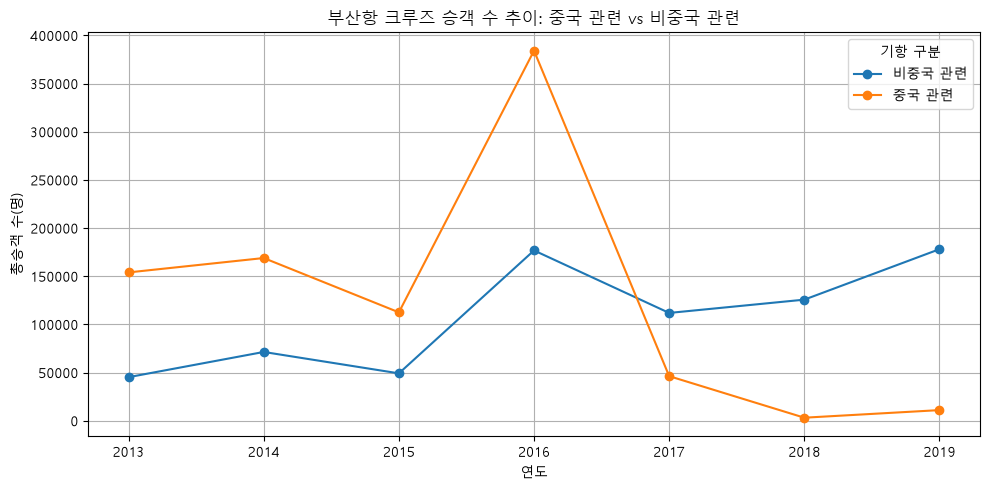

In [56]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

trend = (
    arrival_df[arrival_df["연도"].between(2013, 2019)]
    .groupby(["연도", "중국관련_기항"])
    .agg(
        입항횟수=("선명", "size"),
        총승객수=("승객", "sum")
    )
    .reset_index()
)

trend["구분"] = trend["중국관련_기항"].map({
    True: "중국 관련",
    False: "비중국 관련"
})

# 연도별 총승객 수
passenger_pivot = trend.pivot(
    index="연도",
    columns="구분",
    values="총승객수"
)

ax = passenger_pivot.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

ax.set_title("부산항 크루즈 승객 수 추이: 중국 관련 vs 비중국 관련")
ax.set_xlabel("연도")
ax.set_ylabel("총승객 수(명)")
ax.legend(title="기항 구분")
ax.grid(True)
plt.tight_layout()
plt.show()

In [57]:
import numpy as np
import pandas as pd

# 1. 비교 기간 설정
pandemic_df = arrival_df[
    arrival_df["연도"].between(2017, 2019)
    | arrival_df["연도"].between(2023, 2025)
].copy()

pandemic_df["기간"] = np.where(
    pandemic_df["연도"].between(2017, 2019),
    "팬데믹 이전(2017~2019)",
    "팬데믹 이후(2023~2025)"
)

pandemic_df["구분"] = pandemic_df["중국관련_기항"].map({
    True: "중국 관련",
    False: "비중국 관련"
})

# 2. 기간별·기항 유형별 집계
pandemic_comparison = (
    pandemic_df
    .groupby(["기간", "구분"])
    .agg(
        입항횟수=("선명", "size"),
        총승객수=("승객", "sum"),
        평균승객수=("승객", "mean"),
        중앙승객수=("승객", "median"),
        승객수_결측=("승객", lambda x: x.isna().sum())
    )
    .reset_index()
)

# 3. 연평균 입항 횟수와 승객 수
pandemic_comparison["연평균_입항횟수"] = (
    pandemic_comparison["입항횟수"] / 3
).round(1)

pandemic_comparison["연평균_총승객수"] = (
    pandemic_comparison["총승객수"] / 3
).round(1)

# 4. 결과 출력
print(
    pandemic_comparison[
        [
            "기간", "구분", "입항횟수",
            "연평균_입항횟수", "총승객수",
            "연평균_총승객수", "평균승객수",
            "중앙승객수", "승객수_결측"
        ]
    ].round(1).to_string(index=False)
)

               기간     구분  입항횟수  연평균_입항횟수      총승객수  연평균_총승객수   평균승객수   중앙승객수  승객수_결측
팬데믹 이전(2017~2019) 비중국 관련   246      82.0  415600.0  138533.3  1689.4  1548.5       0
팬데믹 이전(2017~2019)  중국 관련    30      10.0   60376.0   20125.3  2012.5  1929.5       0
팬데믹 이후(2023~2025) 비중국 관련   408     136.0  505682.0  168560.7  1245.5   687.0       2
팬데믹 이후(2023~2025)  중국 관련    16       5.3   57258.0   19086.0  3578.6  4845.5       0


In [58]:
# 기간별 결과를 비교하기 편하게 변환
before_after = pandemic_comparison.pivot(
    index="구분",
    columns="기간",
    values=["입항횟수", "총승객수", "평균승객수"]
)

metrics = ["입항횟수", "총승객수", "평균승객수"]
before_label = "팬데믹 이전(2017~2019)"
after_label = "팬데믹 이후(2023~2025)"

change_rows = []

for category in ["중국 관련", "비중국 관련"]:
    row = {"구분": category}

    for metric in metrics:
        before = before_after.loc[category, (metric, before_label)]
        after = before_after.loc[category, (metric, after_label)]

        row[f"{metric}_이전"] = before
        row[f"{metric}_이후"] = after

        row[f"{metric}_변화율(%)"] = (
            (after - before) / before * 100
            if pd.notna(before) and before != 0
            else np.nan
        )

    change_rows.append(row)

pandemic_change = pd.DataFrame(change_rows)

print(pandemic_change.round(1).to_string(index=False))

    구분  입항횟수_이전  입항횟수_이후  입항횟수_변화율(%)  총승객수_이전  총승객수_이후  총승객수_변화율(%)  평균승객수_이전  평균승객수_이후  평균승객수_변화율(%)
 중국 관련       30       16        -46.7  60376.0  57258.0         -5.2    2012.5    3578.6          77.8
비중국 관련      246      408         65.9 415600.0 505682.0         21.7    1689.4    1245.5         -26.3


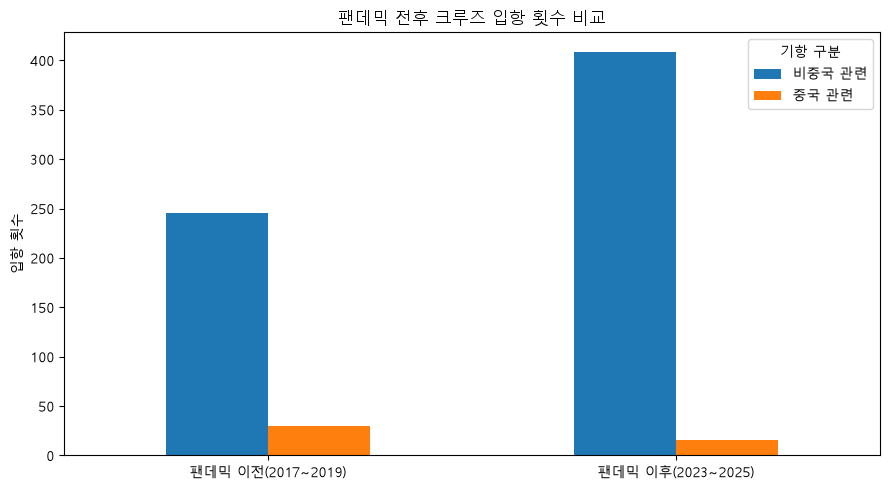

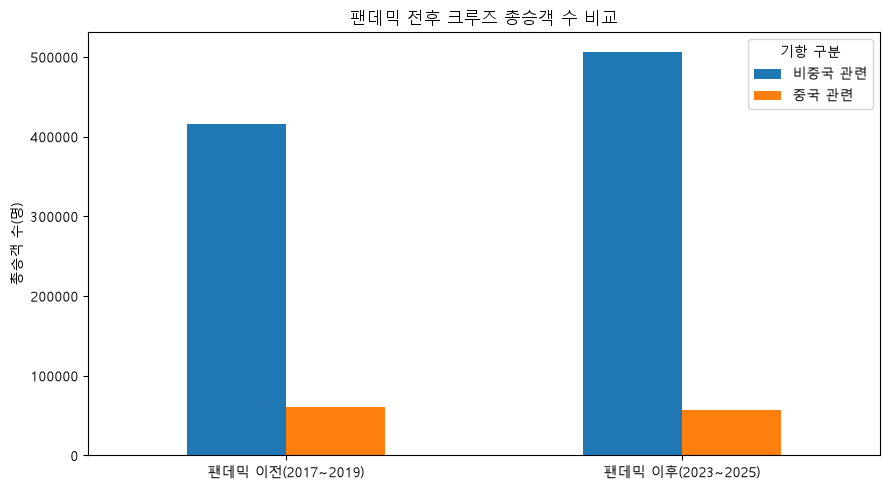

In [59]:
import matplotlib.pyplot as plt

plot_df = pandemic_comparison.pivot(
    index="기간",
    columns="구분",
    values="입항횟수"
)

plot_df = plot_df.reindex([
    "팬데믹 이전(2017~2019)",
    "팬데믹 이후(2023~2025)"
])

ax = plot_df.plot(kind="bar", figsize=(9, 5))
ax.set_title("팬데믹 전후 크루즈 입항 횟수 비교")
ax.set_xlabel("")
ax.set_ylabel("입항 횟수")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="기항 구분")
plt.tight_layout()
plt.show()

# 총승객 수 비교
plot_df_pax = pandemic_comparison.pivot(
    index="기간",
    columns="구분",
    values="총승객수"
).reindex([
    "팬데믹 이전(2017~2019)",
    "팬데믹 이후(2023~2025)"
])

ax = plot_df_pax.plot(kind="bar", figsize=(9, 5))
ax.set_title("팬데믹 전후 크루즈 총승객 수 비교")
ax.set_xlabel("")
ax.set_ylabel("총승객 수(명)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="기항 구분")
plt.tight_layout()
plt.show()

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

# 분석 기간 설정
trend_df = arrival_df[
    arrival_df["연도"].between(2013, 2019)
    | arrival_df["연도"].between(2023, 2025)
].copy()

# 승객 수 숫자형 변환
trend_df["승객"] = pd.to_numeric(
    trend_df["승객"].astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# 연도별·기항 유형별 집계
trend = (
    trend_df
    .groupby(["연도", "중국관련_기항"])
    .agg(
        입항횟수=("선명", "size"),
        총승객수=("승객", "sum")
    )
    .reset_index()
)

trend["구분"] = trend["중국관련_기항"].map({
    True: "중국 관련",
    False: "비중국 관련"
})

print(trend.to_string(index=False))

  연도  중국관련_기항  입항횟수      총승객수     구분
2013    False    43   45216.0 비중국 관련
2013     True    63  153954.0  중국 관련
2014    False    39   71370.0 비중국 관련
2014     True    65  168881.0  중국 관련
2015    False    27   49163.0 비중국 관련
2015     True    37  112491.0  중국 관련
2016    False    85  176758.0 비중국 관련
2016     True   120  384129.0  중국 관련
2017    False    67  111880.0 비중국 관련
2017     True    22   46248.0  중국 관련
2018    False    77  125672.0 비중국 관련
2018     True     3    3123.0  중국 관련
2019    False   102  178048.0 비중국 관련
2019     True     5   11005.0  중국 관련
2023    False   105  151351.0 비중국 관련
2024    False   108  138838.0 비중국 관련
2024     True     6   14054.0  중국 관련
2025    False   195  215493.0 비중국 관련
2025     True    10   43204.0  중국 관련


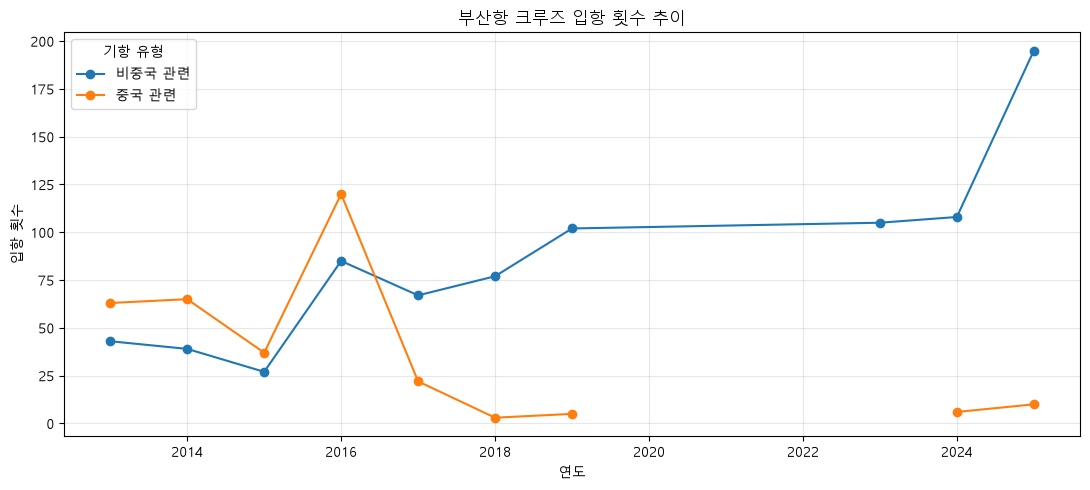

In [61]:
# 연도별 입항 횟수 비교
calls_pivot = trend.pivot(
    index="연도",
    columns="구분",
    values="입항횟수"
)

ax = calls_pivot.plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

ax.set_title("부산항 크루즈 입항 횟수 추이")
ax.set_xlabel("연도")
ax.set_ylabel("입항 횟수")
ax.legend(title="기항 유형")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

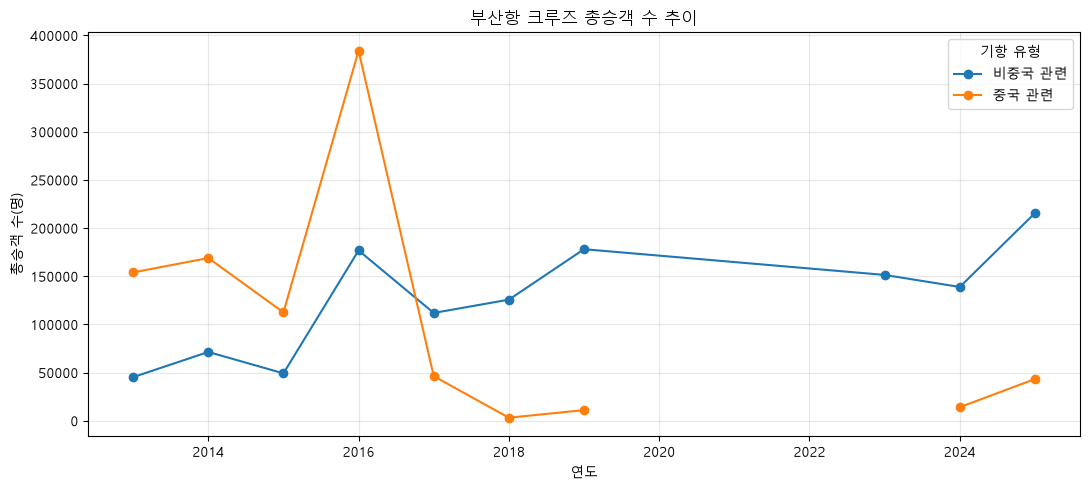

In [62]:
# 연도별 총승객 수 비교
pax_pivot = trend.pivot(
    index="연도",
    columns="구분",
    values="총승객수"
)

ax = pax_pivot.plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

ax.set_title("부산항 크루즈 총승객 수 추이")
ax.set_xlabel("연도")
ax.set_ylabel("총승객 수(명)")
ax.legend(title="기항 유형")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
trend_df = arrival_df[
    arrival_df["연도"].between(2013, 2019)
    | arrival_df["연도"].between(2023, 2025)
].copy()

In [64]:
print("원본 데이터 연도:")
print(sorted(arrival_df["연도"].dropna().unique()))

print("\n그래프용 데이터 연도:")
print(sorted(trend_df["연도"].dropna().unique()))

print("\n연도별 데이터 행 수:")
print(trend_df.groupby("연도").size().to_string())

원본 데이터 연도:
[np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

그래프용 데이터 연도:
[np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2023), np.int32(2024), np.int32(2025)]

연도별 데이터 행 수:
연도
2013    106
2014    104
2015     64
2016    205
2017     89
2018     80
2019    107
2023    105
2024    114
2025    205


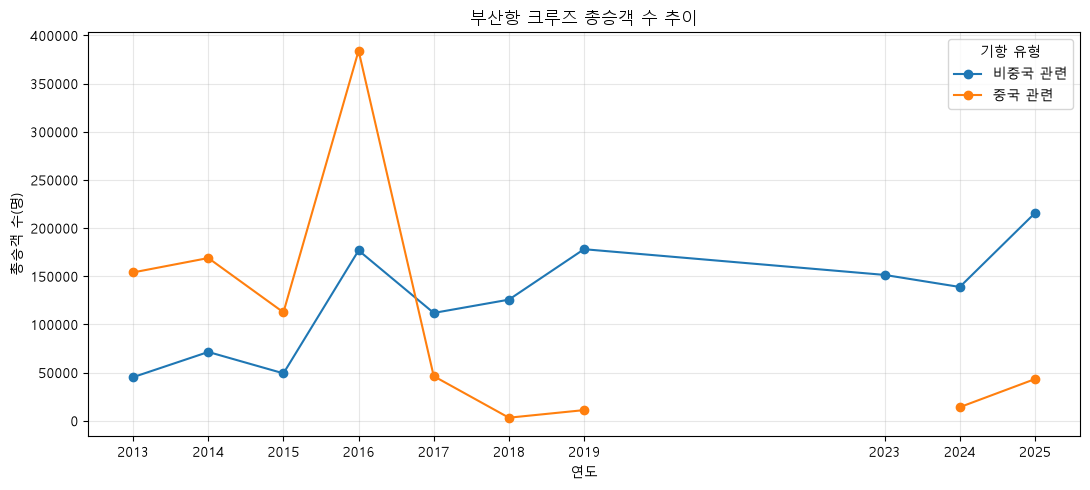

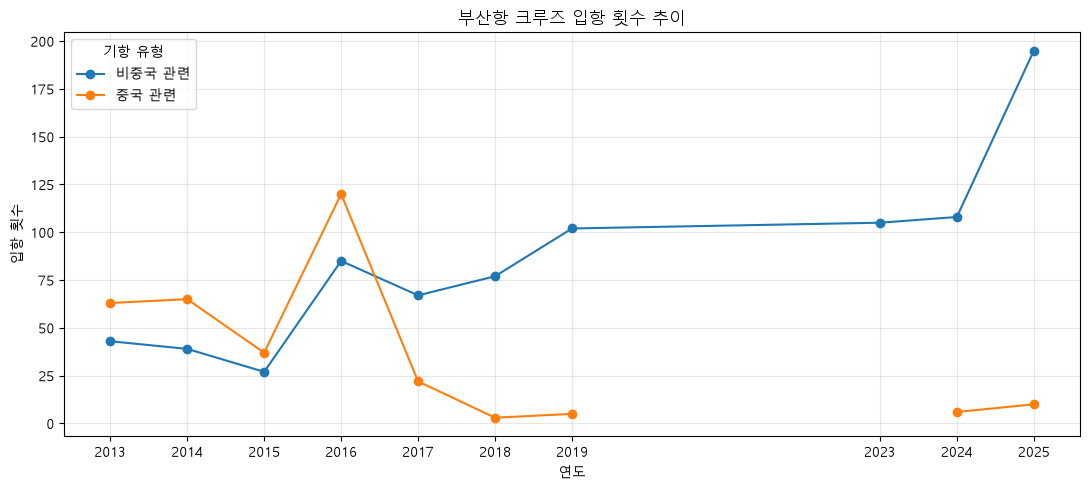

In [65]:
import matplotlib.pyplot as plt

# 실제 데이터가 존재하는 연도만 사용
years = sorted(trend["연도"].unique())

# 연도별 총승객 수
pax_pivot = trend.pivot(
    index="연도",
    columns="구분",
    values="총승객수"
).reindex(years)

ax = pax_pivot.plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

ax.set_title("부산항 크루즈 총승객 수 추이")
ax.set_xlabel("연도")
ax.set_ylabel("총승객 수(명)")
ax.set_xticks(years)  # 실제 데이터 연도만 눈금으로 표시
ax.legend(title="기항 유형")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# 연도별 입항 횟수
calls_pivot = trend.pivot(
    index="연도",
    columns="구분",
    values="입항횟수"
).reindex(years)

ax = calls_pivot.plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

ax.set_title("부산항 크루즈 입항 횟수 추이")
ax.set_xlabel("연도")
ax.set_ylabel("입항 횟수")
ax.set_xticks(years)  # 실제 데이터 연도만 눈금으로 표시
ax.legend(title="기항 유형")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

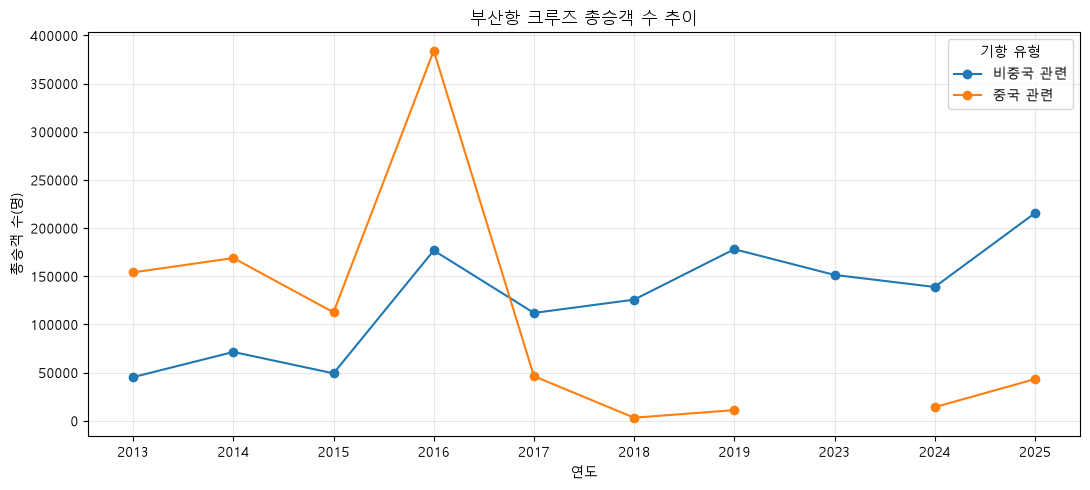

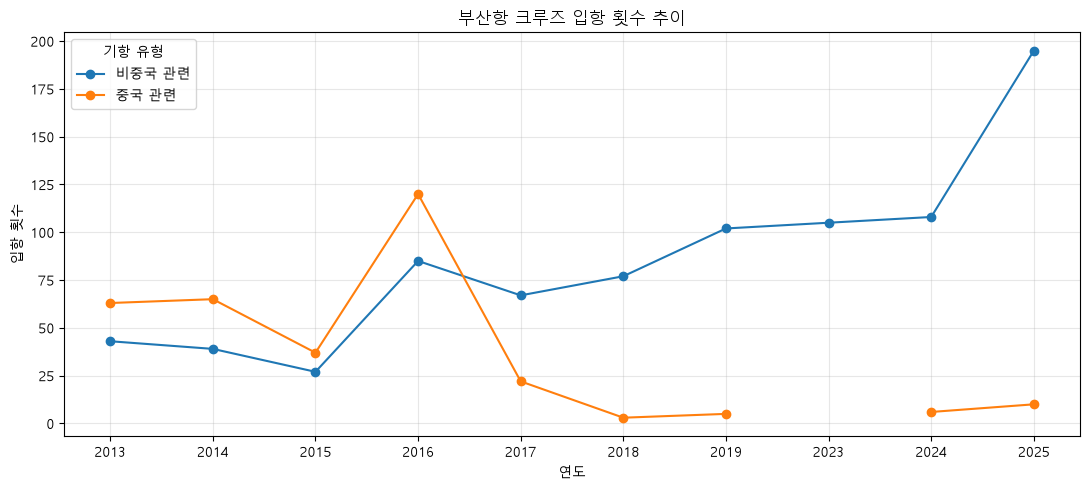

In [66]:
import matplotlib.pyplot as plt
import pandas as pd

# 실제 데이터가 있는 연도만 사용
years = [
    2013, 2014, 2015, 2016, 2017, 2018, 2019,
    2023, 2024, 2025
]

plot_df = trend[trend["연도"].isin(years)].copy()

# 연도를 문자열로 변환해 범주형 x축으로 사용
plot_df["연도_표시"] = plot_df["연도"].astype(str)

# 두 그래프
for value_col, title, ylabel in [
    ("총승객수", "부산항 크루즈 총승객 수 추이", "총승객 수(명)"),
    ("입항횟수", "부산항 크루즈 입항 횟수 추이", "입항 횟수")
]:
    pivot = plot_df.pivot(
        index="연도_표시",
        columns="구분",
        values=value_col
    ).reindex([str(y) for y in years])

    ax = pivot.plot(
        kind="line",
        marker="o",
        figsize=(11, 5)
    )

    ax.set_title(title)
    ax.set_xlabel("연도")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(years)))
    ax.set_xticklabels([str(y) for y in years])
    ax.grid(True, alpha=0.3)
    ax.legend(title="기항 유형")

    plt.tight_layout()
    plt.show()

In [67]:
# 실제 데이터에 기록된 중국 관련 항구명 확인
ports = pd.concat([
    arrival_df["전출항지_정리"],
    arrival_df["차항지_정리"]
]).dropna()

print(
    ports[ports.str.contains(
        "SHANGHAI|TIANJIN|BEIJING|BAOSHAN|DALIAN|QINGDAO|CHINA",
        case=False,
        na=False
    )].value_counts().to_string()
)

SHANGHAI        321
TIANJIN          87
BEIJING          23
BAOSHANMATOU     22
DALIAN           10
QINGDAO           9
SHANGHAI PT       4
QINGDAO PT        1


In [68]:
china_ports = [
    "SHANGHAI",
    "SHANGHAI PT",
    "BAOSHANMATOU",
    "TIANJIN",
    "BEIJING",
    "DALIAN",
    "QINGDAO",
    "QINGDAO PT"
]

arrival_df["전출항지_정리"] = (
    arrival_df["전출항지"]
    .astype("string").str.strip().str.upper()
)

arrival_df["차항지_정리"] = (
    arrival_df["차항지"]
    .astype("string").str.strip().str.upper()
)

arrival_df["중국관련_기항"] = (
    arrival_df["전출항지_정리"].isin(china_ports)
    | arrival_df["차항지_정리"].isin(china_ports)
)

In [69]:
check = (
    arrival_df[
        arrival_df["연도"].isin([
            2013, 2014, 2015, 2016, 2017,
            2018, 2019, 2023, 2024, 2025
        ])
    ]
    .groupby(["연도", "중국관련_기항"])
    .agg(
        입항횟수=("선명", "size"),
        총승객수=("승객", "sum")
    )
    .reset_index()
)

check["구분"] = check["중국관련_기항"].map({
    True: "중국 관련",
    False: "비중국 관련"
})

print(
    check[["연도", "구분", "입항횟수", "총승객수"]]
    .sort_values(["연도", "구분"])
    .to_string(index=False)
)

  연도     구분  입항횟수      총승객수
2013 비중국 관련    43   45216.0
2013  중국 관련    63  153954.0
2014 비중국 관련    39   71370.0
2014  중국 관련    65  168881.0
2015 비중국 관련    27   49163.0
2015  중국 관련    37  112491.0
2016 비중국 관련    85  176758.0
2016  중국 관련   120  384129.0
2017 비중국 관련    67  111880.0
2017  중국 관련    22   46248.0
2018 비중국 관련    77  125672.0
2018  중국 관련     3    3123.0
2019 비중국 관련   102  178048.0
2019  중국 관련     5   11005.0
2023 비중국 관련   105  151351.0
2024 비중국 관련   108  138838.0
2024  중국 관련     6   14054.0
2025 비중국 관련   194  215033.0
2025  중국 관련    11   43664.0


In [70]:
# 2016~2017년 중국 관련 입항 기록 확인
cols = [
    "연도", "선명", "호출부호",
    "전출항지", "차항지", "승객"
]

sample = arrival_df[
    arrival_df["연도"].isin([2016, 2017])
    & arrival_df["중국관련_기항"]
][cols].copy()

sample["승객"] = pd.to_numeric(
    sample["승객"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

print(
    sample.sort_values(["연도", "전출항지", "차항지"])
    .to_string(index=False)
)

  연도                   선명  호출부호              전출항지              차항지      승객
2016  OVATION OF THE SEAS C6BX9           BEIJING          BEIJING  4719.0
2016   LEGEND OF THE SEAS C6SL5           BEIJING FUKUOKA, FUKUOKA  2040.0
2016  OVATION OF THE SEAS C6BX9           BEIJING FUKUOKA, FUKUOKA  4603.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         KUMAMOTO  4799.0
2016            오베이션오브더시즈 C6BX9           BEIJING         NAGASAKI  4591.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         NAGASAKI  4733.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         NAGASAKI  4782.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         NAGASAKI  4788.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         NAGASAKI  4624.0
2016   LEGEND OF THE SEAS C6SL5           BEIJING               제주  2003.0
2016   LEGEND OF THE SEAS C6SL5       BEPPU, OITA          BEIJING  1929.0
2016      CHINESE TAISHAN 3ECP6            DALIAN   HAKATA/FUKUOKA   963.0
2016  OVATION OF THE SEAS

In [71]:
for col in ["입항횟수", "총승객수"]:
    trend = trend.set_index(["연도", "구분"])

    for year in [2013, 2014, 2015, 2016, 2017,
                 2018, 2019, 2023, 2024, 2025]:
        for group in ["중국 관련", "비중국 관련"]:
            if (year, group) not in trend.index:
                trend.loc[(year, group), col] = 0

    trend = trend.reset_index()

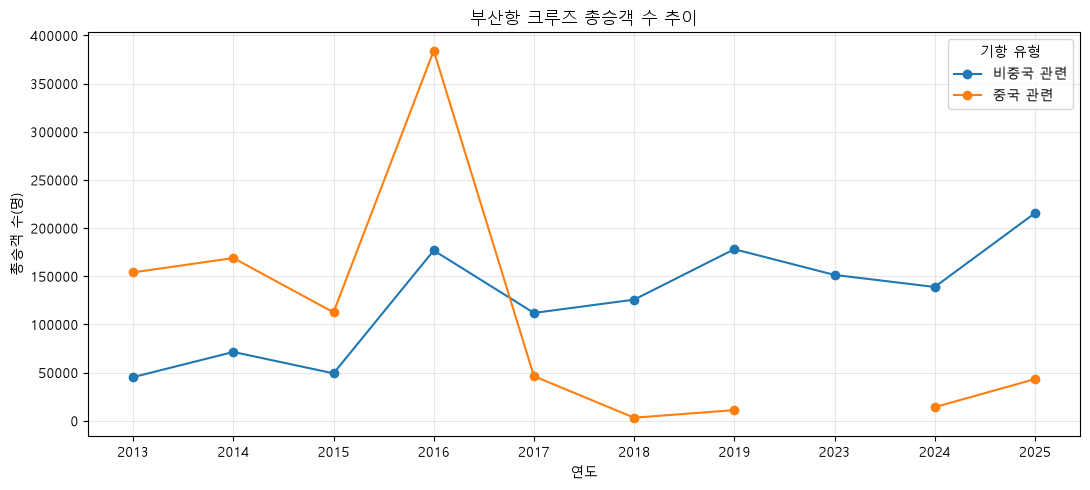

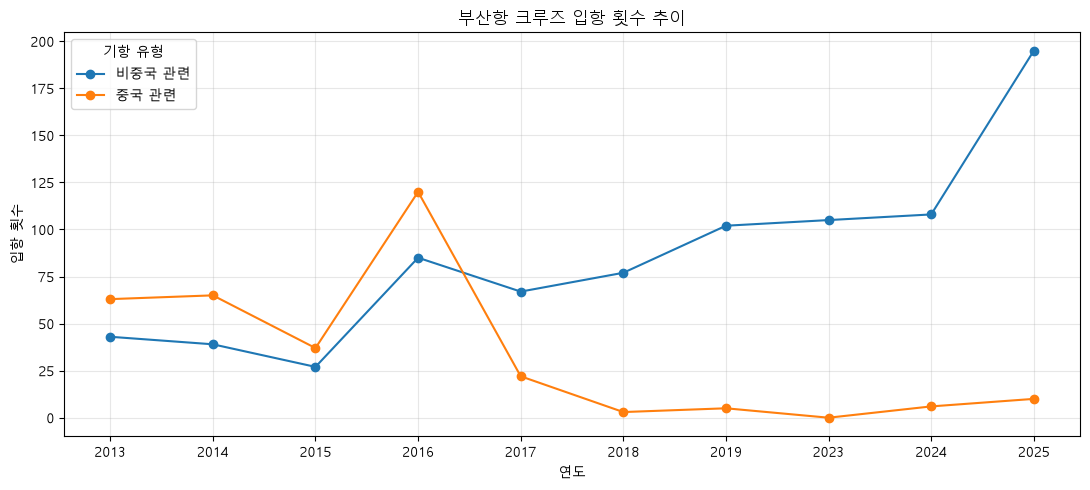

In [72]:
 # 실제 데이터가 있는 연도만 사용
years = [
    2013, 2014, 2015, 2016, 2017, 2018, 2019,
    2023, 2024, 2025
]

plot_df = trend[trend["연도"].isin(years)].copy()

# 연도를 문자열로 변환해 범주형 x축으로 사용
plot_df["연도_표시"] = plot_df["연도"].astype(str)

# 두 그래프
for value_col, title, ylabel in [
    ("총승객수", "부산항 크루즈 총승객 수 추이", "총승객 수(명)"),
    ("입항횟수", "부산항 크루즈 입항 횟수 추이", "입항 횟수")
]:
    pivot = plot_df.pivot(
        index="연도_표시",
        columns="구분",
        values=value_col
    ).reindex([str(y) for y in years])

    ax = pivot.plot(
        kind="line",
        marker="o",
        figsize=(11, 5)
    )

    ax.set_title(title)
    ax.set_xlabel("연도")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(years)))
    ax.set_xticklabels([str(y) for y in years])
    ax.grid(True, alpha=0.3)
    ax.legend(title="기항 유형")

    plt.tight_layout()
    plt.show()

In [73]:
# 2016~2017년 중국 관련 입항 기록 확인
cols = [
    "연도", "선명", "호출부호",
    "전출항지", "차항지", "승객"
]

sample = arrival_df[
    arrival_df["연도"].isin([2016, 2017])
    & arrival_df["중국관련_기항"]
][cols].copy()

sample["승객"] = pd.to_numeric(
    sample["승객"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

print(
    sample.sort_values(["연도", "전출항지", "차항지"])
    .to_string(index=False)
)

  연도                   선명  호출부호              전출항지              차항지      승객
2016  OVATION OF THE SEAS C6BX9           BEIJING          BEIJING  4719.0
2016   LEGEND OF THE SEAS C6SL5           BEIJING FUKUOKA, FUKUOKA  2040.0
2016  OVATION OF THE SEAS C6BX9           BEIJING FUKUOKA, FUKUOKA  4603.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         KUMAMOTO  4799.0
2016            오베이션오브더시즈 C6BX9           BEIJING         NAGASAKI  4591.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         NAGASAKI  4733.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         NAGASAKI  4782.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         NAGASAKI  4788.0
2016  OVATION OF THE SEAS C6BX9           BEIJING         NAGASAKI  4624.0
2016   LEGEND OF THE SEAS C6SL5           BEIJING               제주  2003.0
2016   LEGEND OF THE SEAS C6SL5       BEPPU, OITA          BEIJING  1929.0
2016      CHINESE TAISHAN 3ECP6            DALIAN   HAKATA/FUKUOKA   963.0
2016  OVATION OF THE SEAS